# 01 · Book sanity check

**Goal.** Choose the parameters of the synthetic order flow (`SimParams`) so that the simulated
book behaves like a liquid stock, and document the choice.

**Model.** Cont–Stoikov–Talreja flow (see `docs/notes.pdf`, §2): limit orders arrive at distance
`d` from the opposite best at rate `λ(d) = λ₀ / d^α`; each resting order is cancelled at rate `θ`;
market orders arrive at rate `μ` per side. Order sizes are geometric with mean `m`. Design
decisions D9–D13 in `DESIGN.md`.

**What "liquid" means here.** Spread equal to one tick most of the time (≥ 90 %); the mid moves
a few times per hundred events; a few hundred shares at the best, decreasing with depth but not
empty within the `K` quoted levels; the liquidity floor (D12) almost never triggers.

**How to read.** Sections 1–4 are the diagnostics on the chosen defaults. Section 5 shows the
parameter grid that led to them. Section 6 checks stability across seeds. Conclusions at the end.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpc_execution.simulator import Simulator, SimParams
from mpc_execution.book import Side

%config InlineBackend.figure_format = "retina"
plt.rcParams["figure.figsize"] = (9, 3.5)
%load_ext autoreload
%autoreload 2

In [2]:
def run(params: SimParams, n_events: int, seed: int = 0, n_depth: int = 3) -> tuple[pd.DataFrame, Simulator]:
    """Run n_events and record the observable state (sim. clock, mid, spread and quantity levelwise) after each one."""
    sim = Simulator(params, seed=seed)
    rows = []
    for _ in range(n_events):
        sim._next_event()
        b = sim.book
        row = {"t": sim.t, "mid": b.mid(), "spread": b.spread()}
        for d in range(1, n_depth + 1):
            row[f"bid_q{d}"] = sim._level_qty(Side.BUY, d)
            row[f"ask_q{d}"] = sim._level_qty(Side.SELL, d)
        rows.append(row)
    return pd.DataFrame(rows), sim

### 1 · One trajectory with the chosen defaults
50 000 events. `T` is the simulated time: `n_events / Λ`, with `Λ` the total event rate (≈ 20 here).

In [3]:
p = SimParams()
%time df, sim = run(p, n_events=50_000)
print(f"floor events: {sim.n_floor_events}")
print(f"simulated time: {df.t.iloc[-1]:.1f}")
df.describe().T

CPU times: user 2.56 s, sys: 35.3 ms, total: 2.6 s
Wall time: 2.59 s
floor events: 3
simulated time: 2522.8


,count,mean,std,min,25%,50%,75%,max
t,50000.0,1267.792222,726.730438,0.038047,639.153342,1268.949156,1897.243993,2522.818108
mid,50000.0,10021.511610,8.806918,9998.500000,10018.500000,10023.500000,10028.500000,10035.500000
spread,50000.0,1.056900,0.302827,1.000000,1.000000,1.000000,1.000000,11.000000
bid_q1,50000.0,270.607940,196.930635,0.000000,114.000000,240.000000,394.000000,1283.000000
ask_q1,50000.0,294.131900,211.134335,0.000000,136.000000,260.000000,417.000000,1234.000000
bid_q2,50000.0,190.498940,144.489711,0.000000,83.000000,159.000000,277.000000,1048.000000
ask_q2,50000.0,208.936580,145.353620,0.000000,101.000000,187.000000,287.000000,1013.000000
bid_q3,50000.0,134.094740,124.652841,0.000000,39.000000,105.000000,198.000000,849.000000
ask_q3,50000.0,123.900300,117.575752,0.000000,37.000000,95.000000,171.000000,870.000000


### 2 · Mid price
Expected: a random walk, no trend, no long plateaus. The mid moves when a best level empties
(by market orders or cancellations) and comes back when arrivals at `d = 1` close the spread.

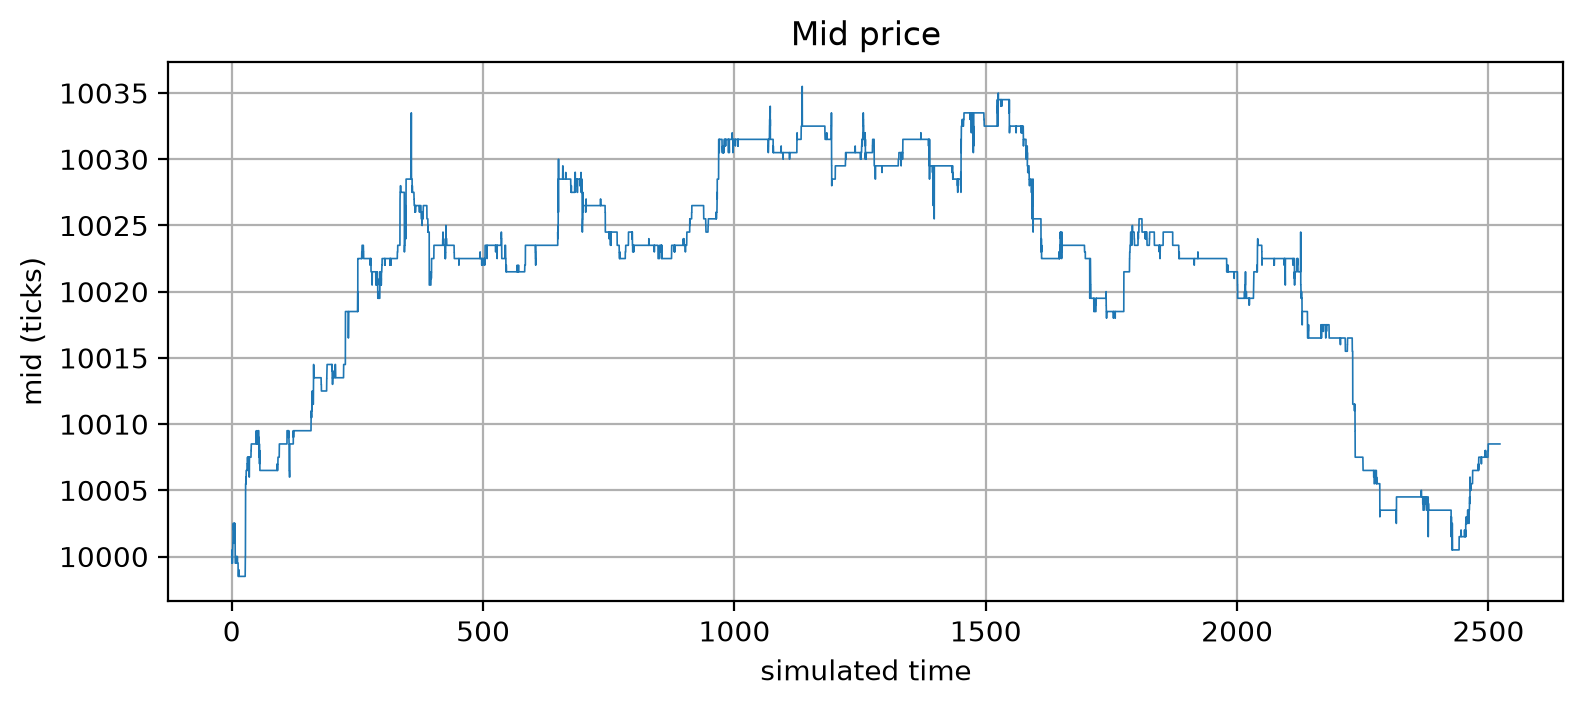

In [4]:
fig, ax = plt.subplots()
ax.plot(df.t, df.mid, lw=0.6)
ax.set(xlabel="simulated time", ylabel="mid (ticks)", title="Mid price")
ax.ticklabel_format(axis="y", useOffset=False)
plt.grid()
fig.savefig("../figures/01_mid.png", dpi=150, bbox_inches="tight")
plt.show()

### 3 · Spread
Expected: mass on 1 tick, a short tail on 2–3. A spread of 2 is the transient after a best level
empties, before the next arrival at `d = 1` refills it.

spread
1    0.95522
2    0.03676
3    0.00556
4    0.00142
5    0.00070
6    0.00024
Name: proportion, dtype: float64
Spread is 1 tick 95.522% of times and is 2 ticks 3.676% of times


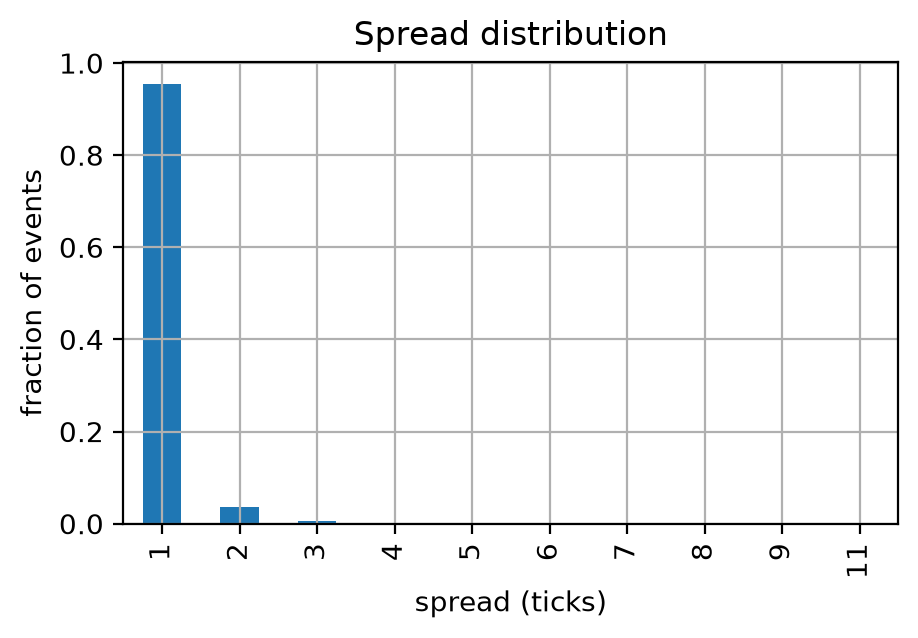

In [5]:
counts = df.spread.value_counts(normalize=True).sort_index()
print(counts.head(6))
fig, ax = plt.subplots(figsize=(5, 3))
counts[:20].plot.bar(ax=ax)
ax.set(xlabel="spread (ticks)", ylabel="fraction of events", title="Spread distribution")
print(f"Spread is 1 tick {round(100 * counts[1],3)}% of times and is 2 ticks {round(100 * counts[2],3)}% of times")
plt.grid()
fig.savefig("../figures/01_spread.png", dpi=150, bbox_inches="tight")
plt.show()

### 4 · Depth profile vs. equilibrium
The CST balance at distance `d` is `λ(d)·m / θ` shares (arrivals `λ(d)·m` against cancellations
`θ·n_d·m`). The simulated profile is measured after a burn-in of 5 000 events, which discards the
seeded configuration (D9). Expected: agreement from `d = 2` on; at `d = 1` the simulated depth is
lower because market orders consume the best, which the balance ignores.

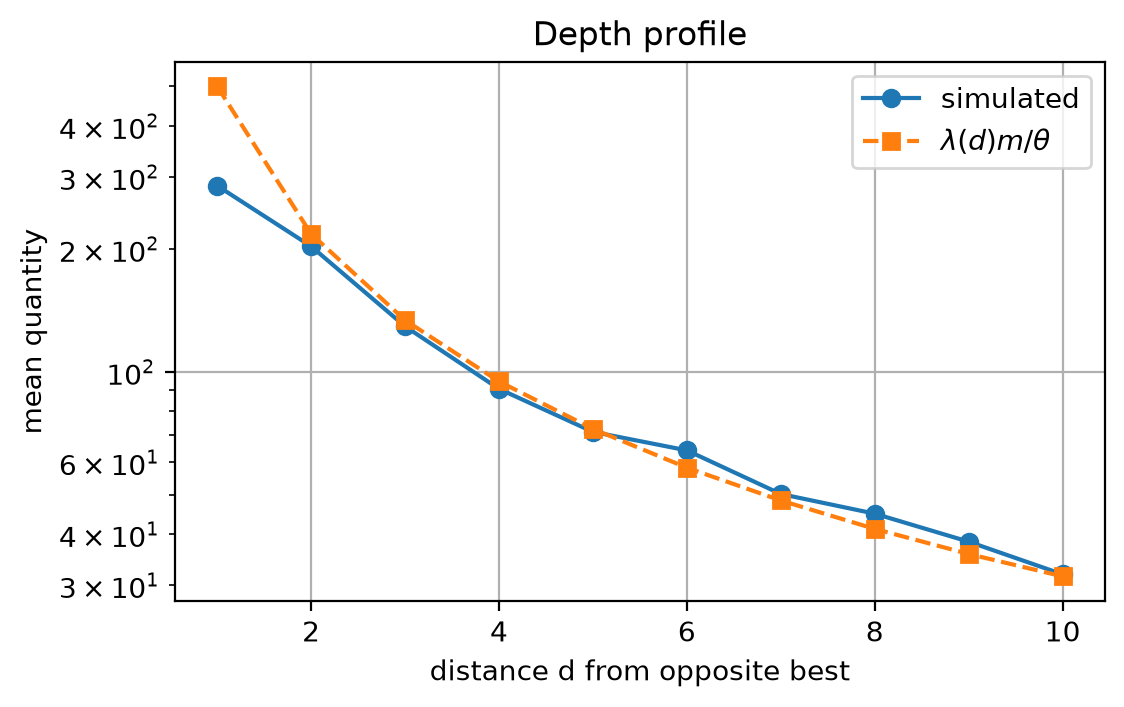

,d,simulated,equilibrium
0,1,285.613867,500.000000
1,2,202.907078,217.637641
2,3,129.229267,133.790260
3,4,90.827722,94.732285
4,5,71.273733,72.477966
5,6,64.205756,58.235593
6,7,50.204433,48.400780
7,8,44.932044,41.234622
8,9,38.367022,35.799667
9,10,31.918733,31.547867


In [6]:
def depth_profile(params: SimParams, n_events: int, seed: int = 0, burn_in: int = 5_000) -> pd.DataFrame:
    """Mean quantity at each distance d, after a burn-in, versus the CST equilibrium."""
    sim = Simulator(params, seed=seed)
    K = params.K
    acc = np.zeros(K)
    n = 0
    for i in range(n_events):
        sim._next_event()
        if i >= burn_in:
            acc += [sim._level_qty(Side.BUY, d) + sim._level_qty(Side.SELL, d) for d in range(1, K + 1)]
            n += 1
    ds = np.arange(1, K + 1)
    return pd.DataFrame({
        "d": ds,
        "simulated": acc / n / 2,                                   # per side
        "equilibrium": params.lam(ds) * params.qty_mean / params.theta,
    })

prof = depth_profile(p, 50_000)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(prof.d, prof.simulated, "o-", label="simulated")
ax.plot(prof.d, prof.equilibrium, "s--", label=r"$\lambda(d) m / \theta$")
ax.set(xlabel="distance d from opposite best", ylabel="mean quantity", title="Depth profile", yscale="log")
ax.legend()
plt.grid()
fig.savefig("../figures/01_depth.png", dpi=150, bbox_inches="tight")
plt.show()
prof

### 4b · Mid changes
Left: non-zero changes are ±½ tick (spread opening or closing) and ±1 tick (a level emptied while the spread was 1).

Right: for a random walk, `Var(Δmid)` over a window of `w` events grows linearly in `w`; the dashed line is that reference. A curve below it for long windows means mean reversion, moderate here.

fraction of events that move the mid: 2.248%
mid
-5.0      1
-3.5      1
-2.5      5
-2.0     12
-1.5     23
-1.0     80
-0.5    429
 0.5    455
 1.0     79
 1.5     19
 2.0     13
 2.5      4
 3.0      1
 3.5      1
 5.0      1
Name: count, dtype: int64


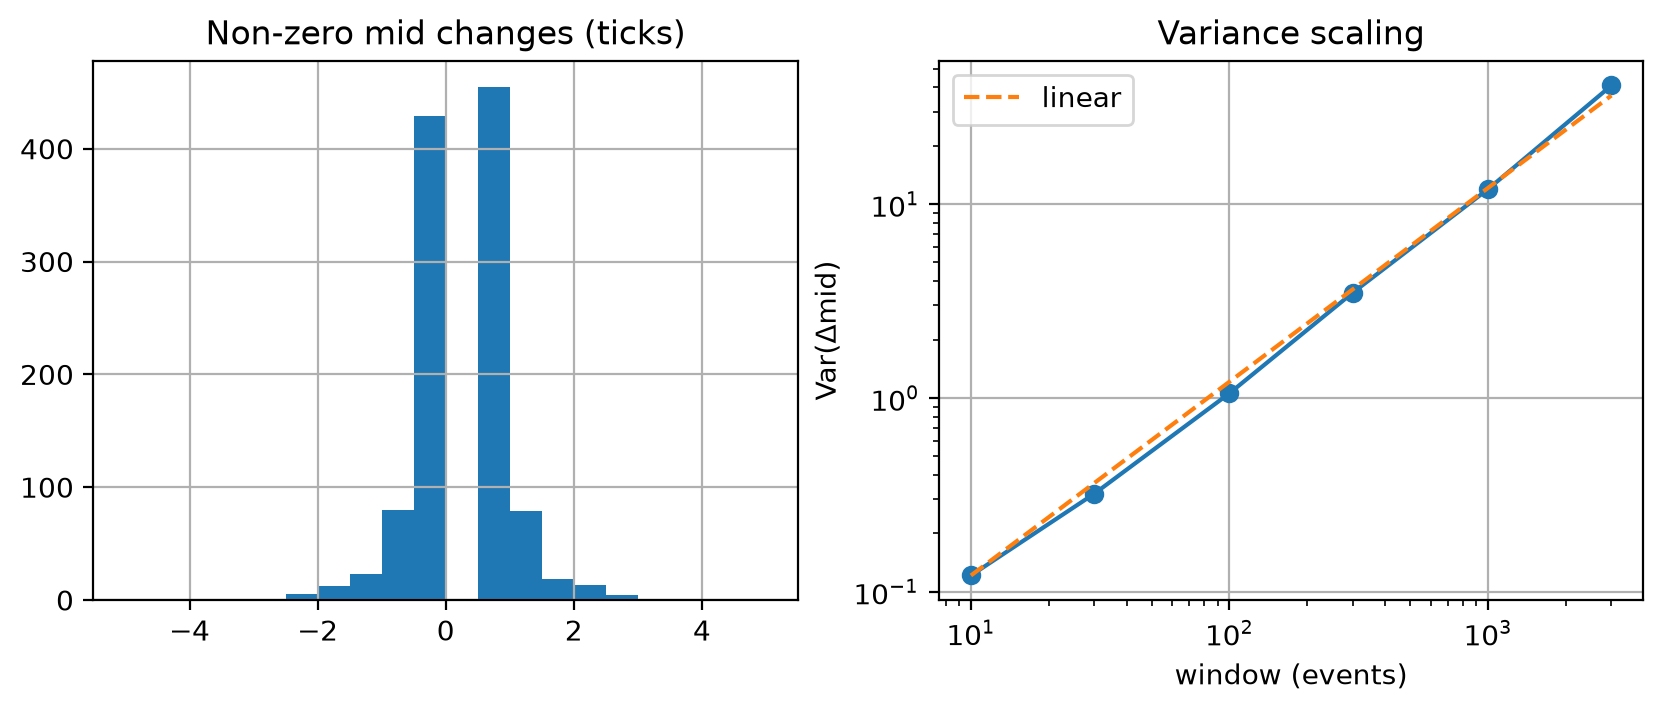

In [7]:
dmid = df.mid.diff().dropna()
print(f"fraction of events that move the mid: {(dmid != 0).mean():.3%}")
print(dmid[dmid != 0].value_counts().sort_index())

windows = [10, 30, 100, 300, 1000, 3000]
var = [df.mid.diff(w).var() for w in windows]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
dmid[dmid != 0].hist(ax=axes[0], bins=20)
axes[0].set(title="Non-zero mid changes (ticks)")
axes[1].loglog(windows, var, "o-")
axes[1].loglog(windows, np.array(windows) * var[0] / windows[0], "--", label="linear")
axes[1].set(xlabel="window (events)", ylabel="Var(Δmid)", title="Variance scaling")
axes[1].legend()
plt.grid()
fig.savefig("../figures/01_mid_changes.png", dpi=150, bbox_inches="tight")
plt.show()

### 5 · How the parameters were chosen
The first grid moves `θ` at fixed `μ`, then `μ`. Depth at the best scales as `λ₀·m/θ`; raising
`μ` thins the book and opens the spread. `α = 1.2` instead of 1.5 thickens the deep levels, which
is what keeps the floor from triggering.

In [8]:
def summary(params: SimParams, n_events: int = 30_000, seed: int = 0) -> dict:
    df, sim = run(params, n_events, seed=seed, n_depth=1)
    dmid = df.mid.diff().dropna()
    return {
        "theta": params.theta, "mu": params.mu, "alpha": params.alpha, "lambda0": params.lambda0,
        "spread=1": (df.spread == 1).mean(),
        "mid moves/100 ev": 100 * (dmid != 0).mean(),
        "best depth": df[["bid_q1", "ask_q1"]].mean().mean(),
        "floor": sim.n_floor_events,
        "T": df.t.iloc[-1],
    }

grid = [
    SimParams(),
    SimParams(theta=0.1),
    SimParams(theta=0.2),
    SimParams(theta=0.15, mu=1.0),
    SimParams(theta=0.15, mu=1.5),
    SimParams(theta=0.2, mu=1.0, alpha=1.2),
    SimParams(theta=0.2, mu=1.5),
    SimParams(theta=0.2, mu=2.0),
    SimParams(theta=0.2, mu=4.0),
    SimParams(theta=0.3, mu=4.0),
    SimParams(theta=0.3, mu=4.0, alpha=1.2),
]

table = pd.DataFrame([summary(q) for q in grid])
table.round(3)

,theta,mu,alpha,lambda0,spread=1,mid moves/100 ev,best depth,floor,T
0,0.20,1.0,1.2,2.0,0.952,2.320,280.852,3,1518.389
1,0.10,1.0,1.2,2.0,0.991,0.417,532.088,0,1517.130
2,0.20,1.0,1.2,2.0,0.952,2.320,280.852,3,1518.389
3,0.15,1.0,1.2,2.0,0.969,1.467,349.950,0,1511.933
4,0.15,1.5,1.2,2.0,0.914,4.353,243.653,0,1530.466
5,0.20,1.0,1.2,2.0,0.952,2.320,280.852,3,1518.389
6,0.20,1.5,1.2,2.0,0.889,5.820,189.339,4,1517.452
7,0.20,2.0,1.2,2.0,0.824,9.927,143.077,13,1521.841
8,0.20,4.0,1.2,2.0,0.611,27.338,60.870,429,1477.396
9,0.30,4.0,1.2,2.0,0.585,29.818,55.401,828,1459.375


### 6 · Stability across seeds

In [9]:
rows = [summary(SimParams(), n_events=50_000, seed=s) for s in (0, 1, 2)]
pd.DataFrame(rows).round(3)

,theta,mu,alpha,lambda0,spread=1,mid moves/100 ev,best depth,floor,T
0,0.2,1.0,1.2,2.0,0.955,2.248,282.370,3,2522.818
1,0.2,1.0,1.2,2.0,0.951,2.582,269.281,4,2528.284
2,0.2,1.0,1.2,2.0,0.954,2.422,270.274,7,2549.039


### Conclusions
Chosen defaults: `λ₀ = 2, α = 1.2, θ = 0.2, μ = 1.0, m = 50, K = 10, floor = 100`.
On three seeds (50 000 events each): spread = 1 tick 95 % of the time; 2.2–2.5 mid changes per
100 events; ≈ 275 shares at the best, ≈ 33 at `d = 10`; floor triggered 1–4 times; variance of
the mid roughly linear in the window. Recorded as D13 in `DESIGN.md`.

Two things this notebook does not settle, left for the execution experiments: the decision
interval `dt` (what matters there is mid changes *per decision step*, not per event), and the
distance of our own candidate orders from the *mid* rather than from the opposite best.